# Motorcyclist Hand-Gesture Recognition — 3-class CNN-BiLSTM (Kaggle)

**Classes:** `bike_left_hand` · `bike_right_hand` · `OOO_bike`
**Dataset:** `iamiqbalshigri/motorcyclist-hand-gesture` → `HandGesture_Dataset/{Training,Testing}`

**Model:** EfficientNet-B0 (ImageNet-pretrained) per-frame encoder → 2-layer **Bi-LSTM** → temporal attention → classifier.

**Key design decisions**
- Only the hand-gesture dataset is used (vehicle classes removed).
- Clip-level **stratified train / val split**; the official `Testing` folder is touched only once, at the end.
- **Segment-based frame sampling** (16 segments across the whole clip; random frame per segment in training, centre frame in eval) so every sample sees the full gesture, and eval is deterministic.
- **Clip-consistent augmentation, no horizontal flips** (a flip would turn *left* into *right*).
- Class imbalance handled **once**, by a `WeightedRandomSampler` (no double-compensation through loss weights).
- Mixed precision (AMP), differential learning rates, warm-up + cosine schedule, early stopping on **val macro-F1** (ties broken by val loss).
- **4 balanced passes over the training clips per epoch** (each pass freshly augmented) → more gradient updates; the previous run only did ~4 steps/epoch.
- **Multi-view test-time inference:** each clip is scored from 5 different frame offsets and the probabilities are averaged — important because clips can be 300+ frames and only 16 are sampled.
- Train accuracy is measured *during* the epoch with augmentation + dropout ON, while val accuracy is measured cleanly in eval mode — so val can legitimately be higher than train early on.

> Kaggle settings: **Accelerator = GPU (T4 x2 / P100)**, **Internet = ON** (needed once to download the pretrained weights), and add the dataset via *Add Input*.

In [1]:
# CELL 1 — Environment check
import torch, torchvision, sklearn, pandas, seaborn
print("torch      :", torch.__version__)
print("torchvision:", torchvision.__version__)
print("CUDA       :", torch.cuda.is_available(),
      "|", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "CPU only — enable GPU in Kaggle settings!")

torch      : 2.11.0+cu130
torchvision: 0.26.0+cu130
CUDA       : True | Tesla T4


In [2]:
# CELL 2 — Locate the Kaggle dataset & verify paths
import os
from pathlib import Path

IMG_EXT = {".png", ".jpg", ".jpeg"}

def find_dir(name, search_root="/kaggle/input", max_depth=6):
    """Find a folder called `name` anywhere under /kaggle/input (robust to Kaggle path changes)."""
    for dirpath, dirnames, _ in os.walk(search_root):
        depth = dirpath[len(search_root):].count(os.sep)
        if name in dirnames:
            return os.path.join(dirpath, name)
        if depth >= max_depth:
            dirnames[:] = []
    return None

# Manual fallback if auto-detect fails (check the "Input" panel on the right in Kaggle):
MANUAL_ROOT = "/kaggle/input/motorcyclist-hand-gesture/HandGesture_Dataset"

GESTURE_ROOT = find_dir("HandGesture_Dataset") or MANUAL_ROOT
GESTURE_TRAIN = f"{GESTURE_ROOT}/Training"
GESTURE_TEST  = f"{GESTURE_ROOT}/Testing"

SAVE_DIR = "/kaggle/working/outputs"
os.makedirs(SAVE_DIR, exist_ok=True)

print("GESTURE_ROOT:", GESTURE_ROOT)
for name, path in [("GESTURE_TRAIN", GESTURE_TRAIN), ("GESTURE_TEST", GESTURE_TEST)]:
    ok = os.path.exists(path)
    print(f"  {'✓' if ok else '✗ NOT FOUND'}  {name}: {path}")
    if ok:
        print("      sub-folders:", sorted(d.name for d in Path(path).iterdir() if d.is_dir()))

# ── helper used everywhere: find "clips" = folders that directly contain frames ──
def list_clips(cls_path):
    """Return [(clip_dir, [sorted frame paths]), ...] for one class folder.
    Works whether frames sit in class/clip/frame.png or deeper."""
    out = []
    for dirpath, _, files in os.walk(cls_path):
        frames = sorted(f for f in files if os.path.splitext(f)[1].lower() in IMG_EXT)
        if frames:
            out.append((dirpath, [os.path.join(dirpath, f) for f in frames]))
    return sorted(out, key=lambda x: x[0])

GESTURE_ROOT: /kaggle/input/datasets/iamiqbalshigri/motorcyclist-hand-gesture/HandGesture_Dataset
  ✓  GESTURE_TRAIN: /kaggle/input/datasets/iamiqbalshigri/motorcyclist-hand-gesture/HandGesture_Dataset/Training
      sub-folders: ['OOO_bike', 'bike_left_hand', 'bike_right_hand']
  ✓  GESTURE_TEST: /kaggle/input/datasets/iamiqbalshigri/motorcyclist-hand-gesture/HandGesture_Dataset/Testing
      sub-folders: ['OOO_bike', 'bike_left_hand', 'bike_right_hand']


In [5]:
# CELL 3 — Config
import torch, random, numpy as np

class Config:
    GESTURE_CLASSES = ["bike_left_hand", "bike_right_hand", "OOO_bike"]
    ALL_CLASSES     = GESTURE_CLASSES
    NUM_CLASSES     = 3

    TRAIN_ROOTS = [(GESTURE_TRAIN, GESTURE_CLASSES)]
    TEST_ROOTS  = [(GESTURE_TEST,  GESTURE_CLASSES)]

    # Clip sampling
    FRAMES_PER_CLIP = 16        # temporal window fed to the Bi-LSTM
    IMG_SIZE        = 224
    MIN_FRAMES      = 4         # skip clips shorter than this

    # Split
    VAL_SPLIT       = 0.15      # of training clips

    # Training
    BATCH_SIZE      = 32        # small data → more optimiser steps per epoch (32 also fits on a T4)
    EPOCHS          = 15
    EPOCH_MULT      = 4         # passes over the (balanced) training clips per epoch
    LR_BACKBONE     = 1e-4      # pretrained CNN  → small LR
    LR_HEAD         = 5e-4      # LSTM + classifier → larger LR
    WEIGHT_DECAY    = 1e-2
    WARMUP_EPOCHS   = 1
    GRAD_CLIP       = 1.0
    PATIENCE        = 8
    LABEL_SMOOTH    = 0.1
    FREEZE_STAGES   = 3         # freeze first N EfficientNet stages (generic edges/textures)
    NUM_WORKERS     = 4
    USE_AMP         = True
    TTA_FRACS       = [0.1, 0.3, 0.5, 0.7, 0.9]   # frame offsets inside each segment at test time

    DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
    SEED   = 42

cfg = Config()
random.seed(cfg.SEED); np.random.seed(cfg.SEED); torch.manual_seed(cfg.SEED)
if cfg.DEVICE == "cuda": torch.cuda.manual_seed_all(cfg.SEED)

print(f"Device  : {cfg.DEVICE}")
print(f"Classes : {cfg.ALL_CLASSES}")

Device  : cuda
Classes : ['bike_left_hand', 'bike_right_hand', 'OOO_bike']


In [6]:
# CELL 4 — Dataset exploration & imbalance report
import pandas as pd

def explore_roots(roots, split_name):
    rows = []
    for root, classes in roots:
        root_path = Path(root)
        if not root_path.exists():
            print(f"[WARN] Not found: {root_path}"); continue
        for cls in classes:
            cls_path = root_path / cls
            if not cls_path.exists():
                print(f"[WARN] Class folder not found: {cls_path}  "
                      f"(available: {[d.name for d in root_path.iterdir() if d.is_dir()]})")
                continue
            clips = list_clips(str(cls_path))
            n_frames = sum(len(f) for _, f in clips)
            rows.append({"Split": split_name, "Class": cls, "Clips": len(clips),
                         "Frames": n_frames,
                         "Avg frames/clip": round(n_frames / max(len(clips), 1))})
    return pd.DataFrame(rows)

df_train = explore_roots(cfg.TRAIN_ROOTS, "Training")
df_test  = explore_roots(cfg.TEST_ROOTS,  "Testing")
df_all   = pd.concat([df_train, df_test], ignore_index=True)

print("=" * 65); print("  DATASET REPORT"); print("=" * 65)
print(df_all.to_string(index=False))

assert len(df_train) == cfg.NUM_CLASSES, "Some class folders are missing — check names printed above."

mx, mn = df_train["Frames"].max(), df_train["Frames"].min()
ratio = mx / max(mn, 1)
print(f"\n  Max={mx:,}  Min={mn:,}  Ratio={ratio:.2f}x")
print(f"  {'⚠  Imbalanced → WeightedRandomSampler + augmentation will be used' if ratio > 1.5 else '✓  Reasonably balanced'}\n")
for _, r in df_train.sort_values("Frames", ascending=False).iterrows():
    bar = "█" * int(r["Frames"] / mx * 35)
    print(f"  {r['Class']:<18} {r['Frames']:>7,} frames  {bar}")

  DATASET REPORT
   Split           Class  Clips  Frames  Avg frames/clip
Training  bike_left_hand     57   10013              176
Training bike_right_hand     54    8693              161
Training        OOO_bike     70    7955              114
 Testing  bike_left_hand     10    3006              301
 Testing bike_right_hand      8    1250              156
 Testing        OOO_bike     26    1609               62

  Max=10,013  Min=7,955  Ratio=1.26x
  ✓  Reasonably balanced

  bike_left_hand      10,013 frames  ███████████████████████████████████
  bike_right_hand      8,693 frames  ██████████████████████████████
  OOO_bike             7,955 frames  ███████████████████████████


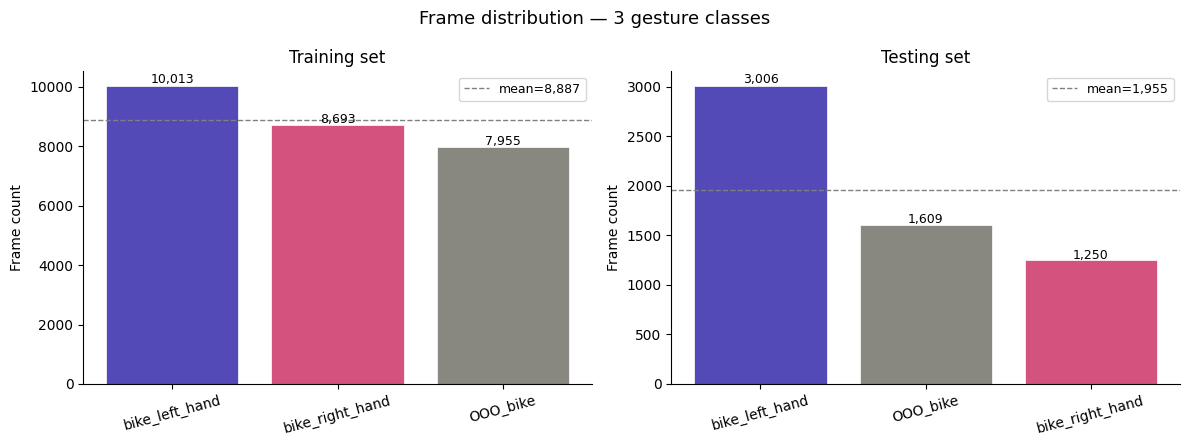

In [7]:
# CELL 5 — Frame distribution plots
import matplotlib.pyplot as plt

palette = {"bike_left_hand": "#534AB7", "bike_right_hand": "#D4537E", "OOO_bike": "#888780"}

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
fig.suptitle("Frame distribution — 3 gesture classes", fontsize=13)

for ax, (split_name, df_sub) in zip(axes, [("Training", df_train), ("Testing", df_test)]):
    df_sub = df_sub.sort_values("Frames", ascending=False)
    colors = [palette.get(c, "#aaa") for c in df_sub["Class"]]
    bars = ax.bar(df_sub["Class"], df_sub["Frames"], color=colors, edgecolor="white", linewidth=0.5)
    ax.axhline(df_sub["Frames"].mean(), color="gray", linestyle="--", linewidth=1,
               label=f"mean={int(df_sub['Frames'].mean()):,}")
    for b, v in zip(bars, df_sub["Frames"]):
        ax.text(b.get_x() + b.get_width()/2, b.get_height() * 1.01, f"{int(v):,}", ha="center", fontsize=9)
    ax.set_title(f"{split_name} set"); ax.set_ylabel("Frame count")
    ax.tick_params(axis="x", rotation=15); ax.legend(fontsize=9)
    ax.spines[["top", "right"]].set_visible(False)

plt.tight_layout()
plt.savefig(f"{SAVE_DIR}/01_frame_distribution.png", dpi=150, bbox_inches="tight")
plt.show()

In [8]:
# CELL 6 — Balancing plan (what the sampler / augmentation will do)
TARGET_FRAMES = int(df_train["Frames"].max())
rows = []
for _, r in df_train.iterrows():
    before = int(r["Frames"])
    rows.append({"Class": r["Class"], "Clips": int(r["Clips"]), "Frames": before,
                 "Sampling weight (rel.)": round(TARGET_FRAMES / max(before, 1), 2)})
plan = pd.DataFrame(rows)
print("=" * 60); print("  BALANCING PLAN"); print("=" * 60)
print(plan.to_string(index=False))
print("\nEach epoch draws classes with ~equal probability (WeightedRandomSampler);")
print("minority classes are re-seen with fresh augmentation each time, so no exact duplicates.")

  BALANCING PLAN
          Class  Clips  Frames  Sampling weight (rel.)
 bike_left_hand     57   10013                    1.00
bike_right_hand     54    8693                    1.15
       OOO_bike     70    7955                    1.26

Each epoch draws classes with ~equal probability (WeightedRandomSampler);
minority classes are re-seen with fresh augmentation each time, so no exact duplicates.


In [9]:
# CELL 7 — Clip-consistent online augmentation (NO flips)
import torchvision.transforms.functional as TF
from PIL import ImageFilter, Image

class OnlineAugment:
    """
    Params are sampled ONCE per clip and applied identically to every frame
    → temporal coherence preserved.
    NO horizontal flip: it would swap 'left hand' and 'right hand'.
    Techniques: colour jitter, blur, small rotation, random crop-zoom, gaussian noise.
    """
    def sample_params(self):
        return {
            "brightness": random.uniform(0.70, 1.40),
            "contrast":   random.uniform(0.80, 1.30),
            "saturation": random.uniform(0.60, 1.50),
            "hue":        random.uniform(-0.05, 0.05),   # small: hue must not change scene semantics much
            "do_blur":    random.random() < 0.30,
            "blur_r":     random.uniform(0.3, 1.5),
            "rotation":   random.uniform(-8, 8),
            "crop_scale": random.uniform(0.80, 1.00),    # zoom-in amount
            "crop_x":     random.random(),               # crop position (0..1)
            "crop_y":     random.random(),
            "noise_std":  random.uniform(0.00, 0.025),
        }

    def apply_pil(self, img, p):
        img = TF.adjust_brightness(img, p["brightness"])
        img = TF.adjust_contrast(img,   p["contrast"])
        img = TF.adjust_saturation(img, p["saturation"])
        img = TF.adjust_hue(img,        p["hue"])
        if p["do_blur"]:
            img = img.filter(ImageFilter.GaussianBlur(p["blur_r"]))
        img = TF.rotate(img, p["rotation"])
        # random crop + resize back to original size
        w, h = img.size
        cw, ch = int(w * p["crop_scale"]), int(h * p["crop_scale"])
        left = int((w - cw) * p["crop_x"]); top = int((h - ch) * p["crop_y"])
        img = TF.resized_crop(img, top, left, ch, cw, [h, w])
        return img

    def apply_noise(self, tensor, std):
        if std > 0:
            tensor = (tensor + torch.randn_like(tensor) * std).clamp(0, 1)
        return tensor

augmentor = OnlineAugment()
print("OnlineAugment ready — colour | blur | rotation | crop-zoom | noise (no flips)")

OnlineAugment ready — colour | blur | rotation | crop-zoom | noise (no flips)


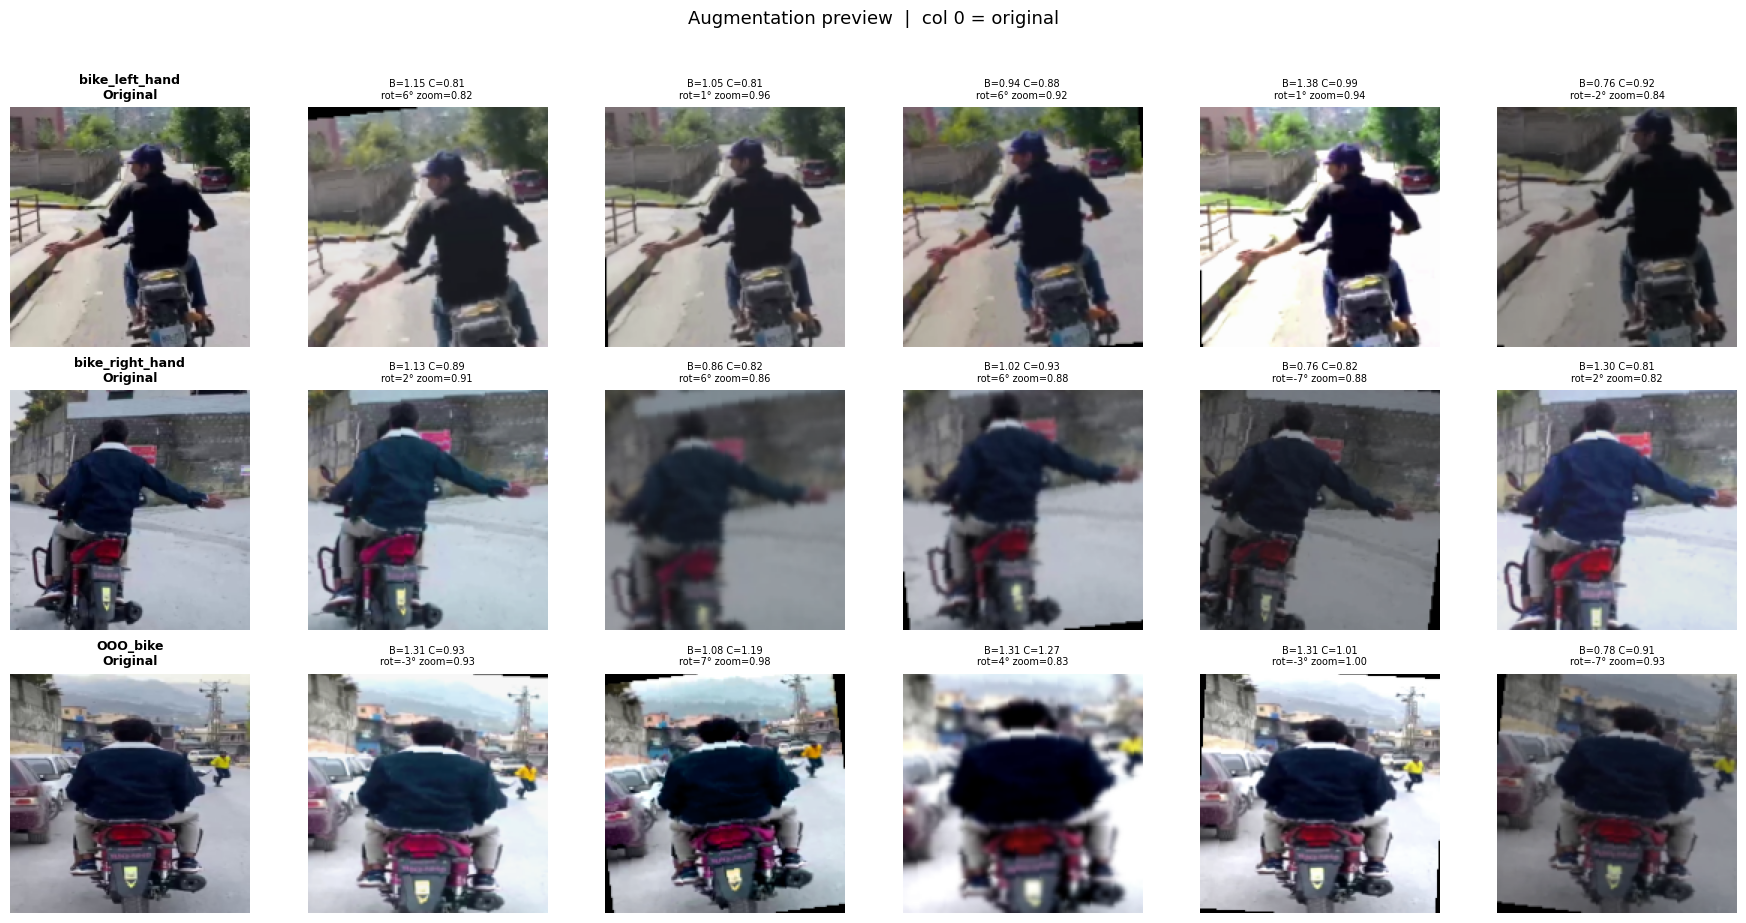

In [10]:
# CELL 8 — Augmentation preview
import torchvision.transforms as T

def load_mid_frame(root, cls):
    clips = list_clips(str(Path(root) / cls))
    if not clips: return None
    frames = clips[0][1]
    return Image.open(frames[len(frames)//2]).convert("RGB")

resize = T.Resize((160, 160), antialias=True)
N_AUG = 5
fig, axes = plt.subplots(cfg.NUM_CLASSES, N_AUG + 1, figsize=(3*(N_AUG+1), 3*cfg.NUM_CLASSES))
fig.suptitle("Augmentation preview  |  col 0 = original", fontsize=13, y=1.02)

for row, cls in enumerate(cfg.ALL_CLASSES):
    orig = load_mid_frame(GESTURE_TRAIN, cls)
    if orig is None:
        for ax in axes[row]: ax.axis("off")
        axes[row][0].set_title(f"{cls}\n[not found]", fontsize=8); continue
    orig_r = resize(orig)
    axes[row][0].imshow(orig_r); axes[row][0].axis("off")
    axes[row][0].set_title(f"{cls}\nOriginal", fontsize=9, fontweight="bold")
    for col in range(1, N_AUG + 1):
        p = augmentor.sample_params()
        axes[row][col].imshow(augmentor.apply_pil(orig_r.copy(), p)); axes[row][col].axis("off")
        axes[row][col].set_title(f"B={p['brightness']:.2f} C={p['contrast']:.2f}\nrot={p['rotation']:.0f}° zoom={p['crop_scale']:.2f}", fontsize=7)

plt.tight_layout()
plt.savefig(f"{SAVE_DIR}/03_augmentation_preview.png", dpi=150, bbox_inches="tight")
plt.show()

In [11]:
# CELL 9 — Clip indexer + stratified train / val split
from sklearn.model_selection import train_test_split
from collections import Counter

def index_clips(roots):
    """Return list of (frame_paths, label_idx, class_name)."""
    class_to_idx = {c: i for i, c in enumerate(cfg.ALL_CLASSES)}
    clips = []
    for root, classes in roots:
        for cls in classes:
            cls_path = Path(root) / cls
            if not cls_path.exists(): continue
            for _, frames in list_clips(str(cls_path)):
                if len(frames) < cfg.MIN_FRAMES: continue
                clips.append((frames, class_to_idx[cls], cls))
    return clips

all_train_clips = index_clips(cfg.TRAIN_ROOTS)
test_clips      = index_clips(cfg.TEST_ROOTS)

train_clips, val_clips = train_test_split(
    all_train_clips, test_size=cfg.VAL_SPLIT,
    stratify=[c[1] for c in all_train_clips], random_state=cfg.SEED)

print("=" * 60); print("  TRAIN / VAL / TEST SPLIT"); print("=" * 60)
for name, split in [("Train", train_clips), ("Val", val_clips), ("Test", test_clips)]:
    dist = Counter(c[2] for c in split)
    print(f"\n  {name}  ({len(split)} clips)")
    for cls in cfg.ALL_CLASSES:
        n = dist.get(cls, 0)
        print(f"    {cls:<18} {n:>4} clips  {'█' * int(n / max(max(dist.values()), 1) * 25)}")

  TRAIN / VAL / TEST SPLIT

  Train  (153 clips)
    bike_left_hand       48 clips  ████████████████████
    bike_right_hand      46 clips  ███████████████████
    OOO_bike             59 clips  █████████████████████████

  Val  (28 clips)
    bike_left_hand        9 clips  ████████████████████
    bike_right_hand       8 clips  ██████████████████
    OOO_bike             11 clips  █████████████████████████

  Test  (44 clips)
    bike_left_hand       10 clips  █████████
    bike_right_hand       8 clips  ███████
    OOO_bike             26 clips  █████████████████████████


In [12]:
# CELL 10 — Dataset (segment sampling) + loaders
from torch.utils.data import Dataset, DataLoader, WeightedRandomSampler

class ClipDataset(Dataset):
    """
    Segment-based sampling (TSN-style): the clip is split into FRAMES_PER_CLIP equal
    segments; training picks a random frame per segment, evaluation picks the middle one
    → full temporal coverage, and deterministic val/test results.
    """
    def __init__(self, clips, augment=False, verbose=True):
        self.clips     = list(clips)
        self.augment   = augment
        self.augmentor = OnlineAugment()
        self.resize    = T.Resize((cfg.IMG_SIZE, cfg.IMG_SIZE), antialias=True)
        self.to_tensor = T.ToTensor()
        self.normalize = T.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])
        if verbose:
            dist = Counter(c[1] for c in self.clips)
            print(f"  clips={len(self.clips)}  augment={augment}  " +
                  "  ".join(f"{cls}={dist.get(i,0)}" for i, cls in enumerate(cfg.ALL_CLASSES)))

    def __len__(self): return len(self.clips)

    def _sample_frames(self, paths):
        n, T_len = len(paths), cfg.FRAMES_PER_CLIP
        edges = np.linspace(0, n, T_len + 1)
        idxs = []
        for i in range(T_len):
            lo = min(int(edges[i]), n - 1)
            hi = min(max(lo + 1, int(edges[i + 1])), n)
            idxs.append(random.randint(lo, hi - 1) if self.augment else (lo + hi - 1) // 2)
        return [paths[i] for i in idxs]

    def __getitem__(self, idx):
        frame_paths, label, _ = self.clips[idx]
        pil_frames = [self.resize(Image.open(p).convert("RGB")) for p in self._sample_frames(frame_paths)]
        if self.augment:
            params = self.augmentor.sample_params()
            pil_frames = [self.augmentor.apply_pil(f, params) for f in pil_frames]
            noise_std = params["noise_std"]
        tensors = []
        for f in pil_frames:
            t = self.to_tensor(f)
            if self.augment: t = self.augmentor.apply_noise(t, noise_std)
            tensors.append(self.normalize(t))
        return torch.stack(tensors), label          # (T, C, H, W), int


def build_sampler(dataset):
    labels  = [c[1] for c in dataset.clips]
    counts  = np.bincount(labels, minlength=cfg.NUM_CLASSES).astype(float)
    weights = 1.0 / (counts + 1e-6)
    return WeightedRandomSampler([weights[l] for l in labels],
                                 num_samples=len(labels) * cfg.EPOCH_MULT, replacement=True)

print("Train:"); train_ds = ClipDataset(train_clips, augment=True)
print("Val  :"); val_ds   = ClipDataset(val_clips,   augment=False)
print("Test :"); test_ds  = ClipDataset(test_clips,  augment=False)

loader_kw = dict(batch_size=cfg.BATCH_SIZE, num_workers=cfg.NUM_WORKERS,
                 pin_memory=(cfg.DEVICE == "cuda"), persistent_workers=cfg.NUM_WORKERS > 0)
train_loader = DataLoader(train_ds, sampler=build_sampler(train_ds), drop_last=True, **loader_kw)
val_loader   = DataLoader(val_ds,   shuffle=False, **loader_kw)
test_loader  = DataLoader(test_ds,  shuffle=False, **loader_kw)

print(f"\nBatches → train {len(train_loader)} | val {len(val_loader)} | test {len(test_loader)}")

Train:
  clips=153  augment=True  bike_left_hand=48  bike_right_hand=46  OOO_bike=59
Val  :
  clips=28  augment=False  bike_left_hand=9  bike_right_hand=8  OOO_bike=11
Test :
  clips=44  augment=False  bike_left_hand=10  bike_right_hand=8  OOO_bike=26

Batches → train 19 | val 1 | test 2


In [13]:
# CELL 11 — Model: EfficientNet-B0 → Bi-LSTM → Temporal Attention → Classifier
import torch.nn as nn
import torch.nn.functional as F
import torchvision.models as models

class CNNEncoder(nn.Module):
    """Per-frame spatial feature extractor (ImageNet-pretrained EfficientNet-B0, 1280-d)."""
    def __init__(self, out_dim=256, pretrained=True, freeze_stages=3):
        super().__init__()
        weights = models.EfficientNet_B0_Weights.DEFAULT if pretrained else None
        try:
            bb = models.efficientnet_b0(weights=weights)
        except Exception as e:
            print("⚠ Could not download pretrained weights (turn Internet ON in Kaggle settings).")
            print("  Falling back to RANDOM init — accuracy will be much worse.\n  Error:", e)
            bb = models.efficientnet_b0(weights=None)
        self.features = bb.features
        self.pool     = nn.AdaptiveAvgPool2d(1)
        self.proj = nn.Sequential(
            nn.Flatten(),
            nn.Linear(1280, out_dim),
            nn.LayerNorm(out_dim),        # LayerNorm: independent of frame-batch statistics
            nn.GELU(),
            nn.Dropout(0.3),
        )
        for stage in list(self.features)[:freeze_stages]:      # freeze generic low-level stages
            for p in stage.parameters(): p.requires_grad = False

    def forward(self, x):
        return self.proj(self.pool(self.features(x)))


class TemporalAttention(nn.Module):
    """Learns which frames of the sequence matter most."""
    def __init__(self, hidden):
        super().__init__()
        self.fc = nn.Sequential(nn.Linear(hidden, 128), nn.Tanh(), nn.Linear(128, 1))
    def forward(self, seq):
        w = F.softmax(self.fc(seq), dim=1)
        return (seq * w).sum(dim=1)


class CNNBiLSTM(nn.Module):
    def __init__(self, num_classes=3, feat_dim=256, hidden=256, lstm_layers=2, dropout=0.4,
                 pretrained=True, freeze_stages=3):
        super().__init__()
        self.encoder = CNNEncoder(feat_dim, pretrained, freeze_stages)
        self.lstm = nn.LSTM(feat_dim, hidden, num_layers=lstm_layers, batch_first=True,
                            bidirectional=True, dropout=dropout if lstm_layers > 1 else 0.0)
        self.attention = TemporalAttention(hidden * 2)
        self.head = nn.Sequential(
            nn.Dropout(dropout), nn.Linear(hidden * 2, 128), nn.GELU(),
            nn.Dropout(dropout * 0.5), nn.Linear(128, num_classes))

    def forward(self, x):                       # x: (B, T, C, H, W)
        B, T, C, H, W = x.shape
        feats = self.encoder(x.reshape(B * T, C, H, W)).view(B, T, -1)
        out, _ = self.lstm(feats)
        return self.head(self.attention(out))


model = CNNBiLSTM(num_classes=cfg.NUM_CLASSES, freeze_stages=cfg.FREEZE_STAGES).to(cfg.DEVICE)

n_total = sum(p.numel() for p in model.parameters())
n_train = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(f"Params: {n_total:,} total | {n_train:,} trainable")

model.eval()
with torch.no_grad():
    out = model(torch.zeros(2, cfg.FRAMES_PER_CLIP, 3, cfg.IMG_SIZE, cfg.IMG_SIZE, device=cfg.DEVICE))
print(f"Output shape: {tuple(out.shape)}  ← expected (2, {cfg.NUM_CLASSES})")

Downloading: "https://download.pytorch.org/models/efficientnet_b0_rwightman-7f5810bc.pth" to /root/.cache/torch/hub/checkpoints/efficientnet_b0_rwightman-7f5810bc.pth


100%|██████████| 20.5M/20.5M [00:00<00:00, 141MB/s] 


Params: 7,097,472 total | 7,078,382 trainable
Output shape: (2, 3)  ← expected (2, 3)


In [14]:
# CELL 12 — Training (AMP, warm-up + cosine, early stopping on val macro-F1)
import math, torch.optim as optim
from torch.optim.lr_scheduler import LambdaLR
from sklearn.metrics import f1_score
from tqdm.auto import tqdm

# Imbalance is handled by the WeightedRandomSampler → plain loss (no extra class weights)
criterion = nn.CrossEntropyLoss(label_smoothing=cfg.LABEL_SMOOTH)

backbone_params = [p for p in model.encoder.features.parameters() if p.requires_grad]
head_params     = [p for n, p in model.named_parameters()
                   if p.requires_grad and not n.startswith("encoder.features")]
optimizer = optim.AdamW([
    {"params": backbone_params, "lr": cfg.LR_BACKBONE},
    {"params": head_params,     "lr": cfg.LR_HEAD},
], weight_decay=cfg.WEIGHT_DECAY)

def lr_lambda(epoch):                       # linear warm-up → cosine decay
    if epoch < cfg.WARMUP_EPOCHS:
        return (epoch + 1) / cfg.WARMUP_EPOCHS
    prog = (epoch - cfg.WARMUP_EPOCHS) / max(1, cfg.EPOCHS - cfg.WARMUP_EPOCHS)
    return 0.01 + 0.99 * 0.5 * (1 + math.cos(math.pi * prog))
scheduler = LambdaLR(optimizer, lr_lambda)

use_amp = cfg.USE_AMP and cfg.DEVICE == "cuda"
scaler  = torch.amp.GradScaler("cuda", enabled=use_amp)

history = {"train_loss": [], "train_acc": [], "val_loss": [], "val_acc": [], "val_f1": []}
best_f1, best_loss, patience = -1.0, float("inf"), 0

def run_epoch(loader, train):
    model.train() if train else model.eval()
    total_loss, total = 0.0, 0
    preds, labs = [], []
    with torch.set_grad_enabled(train):
        for clips, labels in tqdm(loader, leave=False, desc="Train" if train else "Val"):
            clips  = clips.to(cfg.DEVICE, non_blocking=True)
            labels = labels.to(cfg.DEVICE, non_blocking=True)
            with torch.autocast(device_type=cfg.DEVICE, dtype=torch.float16, enabled=use_amp):
                logits = model(clips)
                loss   = criterion(logits, labels)
            if train:
                optimizer.zero_grad(set_to_none=True)
                scaler.scale(loss).backward()
                scaler.unscale_(optimizer)
                nn.utils.clip_grad_norm_(model.parameters(), cfg.GRAD_CLIP)
                scaler.step(optimizer); scaler.update()
            total_loss += loss.item() * labels.size(0); total += labels.size(0)
            preds.extend(logits.argmax(1).cpu().tolist()); labs.extend(labels.cpu().tolist())
    acc = float(np.mean(np.array(preds) == np.array(labs)))
    f1  = f1_score(labs, preds, average="macro", labels=list(range(cfg.NUM_CLASSES)), zero_division=0)
    return total_loss / total, acc, f1

print(f"Training on {cfg.DEVICE} | AMP={use_amp} | {cfg.EPOCHS} epochs\n")
print(f"{'Epoch':>5}  {'TrLoss':>7}  {'TrAcc':>6}  {'VlLoss':>7}  {'VlAcc':>6}  {'VlF1':>6}  Note")
print("-" * 68)

for epoch in range(1, cfg.EPOCHS + 1):
    tr_loss, tr_acc, _       = run_epoch(train_loader, train=True)
    vl_loss, vl_acc, vl_f1   = run_epoch(val_loader,   train=False)
    scheduler.step()

    for k, v in zip(history, [tr_loss, tr_acc, vl_loss, vl_acc, vl_f1]): history[k].append(v)

    improved = (vl_f1 > best_f1 + 1e-4) or (abs(vl_f1 - best_f1) <= 1e-4 and vl_loss < best_loss)
    if improved:
        best_f1, best_loss, patience, note = vl_f1, vl_loss, 0, "<-- best ✓"
        torch.save({"epoch": epoch, "state": model.state_dict(), "val_acc": vl_acc,
                    "val_f1": vl_f1, "classes": cfg.ALL_CLASSES}, f"{SAVE_DIR}/best_model.pt")
    else:
        patience += 1; note = f"patience {patience}/{cfg.PATIENCE}"

    print(f"{epoch:>5}  {tr_loss:>7.4f}  {tr_acc:>6.3f}  {vl_loss:>7.4f}  {vl_acc:>6.3f}  {vl_f1:>6.3f}  {note}")
    if patience >= cfg.PATIENCE:
        print(f"\nEarly stop at epoch {epoch}."); break

print(f"\nBest val macro-F1 : {best_f1:.4f}  (val loss {best_loss:.4f})")
print("Note: train acc is measured with augmentation + dropout ON while the weights change; val acc is a clean eval-mode pass.")
print(f"Checkpoint        : {SAVE_DIR}/best_model.pt")

Training on cuda | AMP=True | 15 epochs

Epoch   TrLoss   TrAcc   VlLoss   VlAcc    VlF1  Note
--------------------------------------------------------------------


Train:   0%|          | 0/19 [00:00<?, ?it/s]

Val:   0%|          | 0/1 [00:00<?, ?it/s]

    1   0.9432   0.615   0.7176   0.750   0.708  <-- best ✓


Train:   0%|          | 0/19 [00:00<?, ?it/s]

Val:   0%|          | 0/1 [00:00<?, ?it/s]

... (27 outputs left out)

   11   0.3034   0.997   0.3989   0.964   0.966  patience 7/8


Train:   0%|          | 0/19 [00:00<?, ?it/s]

Val:   0%|          | 0/1 [00:00<?, ?it/s]

   12   0.2995   0.998   0.4021   0.964   0.966  patience 8/8

Early stop at epoch 12.

Best val macro-F1 : 0.9659  (val loss 0.3810)
Note: train acc is measured with augmentation + dropout ON while the weights change; val acc is a clean eval-mode pass.
Checkpoint        : /kaggle/working/outputs/best_model.pt


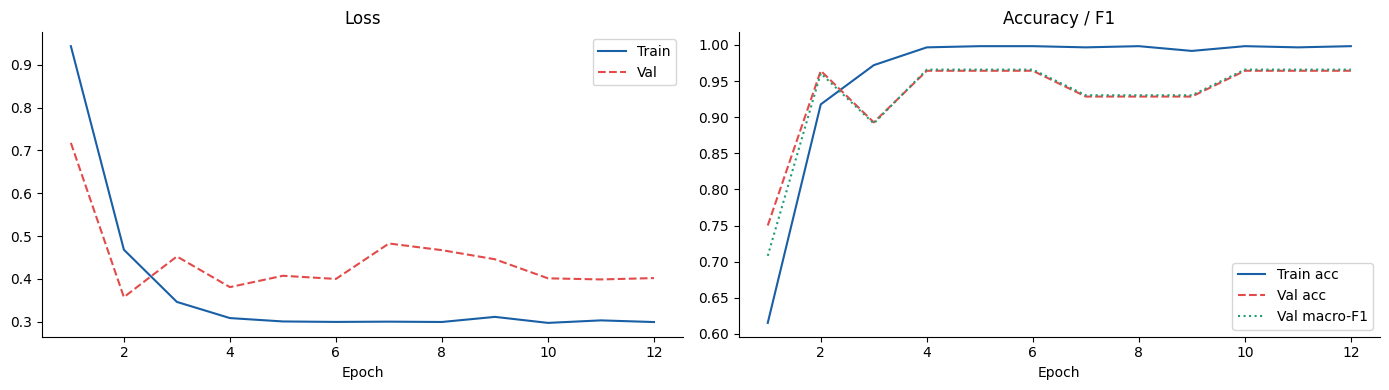

In [15]:
# CELL 13 — Training curves
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 4))
ep = range(1, len(history["train_loss"]) + 1)

ax1.plot(ep, history["train_loss"], label="Train", color="#185FA5")
ax1.plot(ep, history["val_loss"],   label="Val",   color="#E24B4A", linestyle="--")
ax1.set_title("Loss"); ax1.set_xlabel("Epoch"); ax1.legend()

ax2.plot(ep, history["train_acc"], label="Train acc", color="#185FA5")
ax2.plot(ep, history["val_acc"],   label="Val acc",   color="#E24B4A", linestyle="--")
ax2.plot(ep, history["val_f1"],    label="Val macro-F1", color="#1D9E75", linestyle=":")
ax2.set_title("Accuracy / F1"); ax2.set_xlabel("Epoch"); ax2.legend()

for a in (ax1, ax2): a.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.savefig(f"{SAVE_DIR}/04_training_curves.png", dpi=150, bbox_inches="tight")
plt.show()

Loaded best checkpoint — epoch 4 | val acc 0.9643 | val F1 0.9659


view 0.1:   0%|          | 0/2 [00:00<?, ?it/s]

view 0.3:   0%|          | 0/2 [00:00<?, ?it/s]

view 0.5:   0%|          | 0/2 [00:00<?, ?it/s]

view 0.7:   0%|          | 0/2 [00:00<?, ?it/s]

view 0.9:   0%|          | 0/2 [00:00<?, ?it/s]


Single view  : acc 1.0000 | macro-F1 1.0000
Multi-view x5: acc 1.0000 | macro-F1 1.0000

  CLASSIFICATION REPORT — Test Set (multi-view)
                 precision    recall  f1-score   support

 bike_left_hand     1.0000    1.0000    1.0000        10
bike_right_hand     1.0000    1.0000    1.0000         8
       OOO_bike     1.0000    1.0000    1.0000        26

       accuracy                         1.0000        44
      macro avg     1.0000    1.0000    1.0000        44
   weighted avg     1.0000    1.0000    1.0000        44



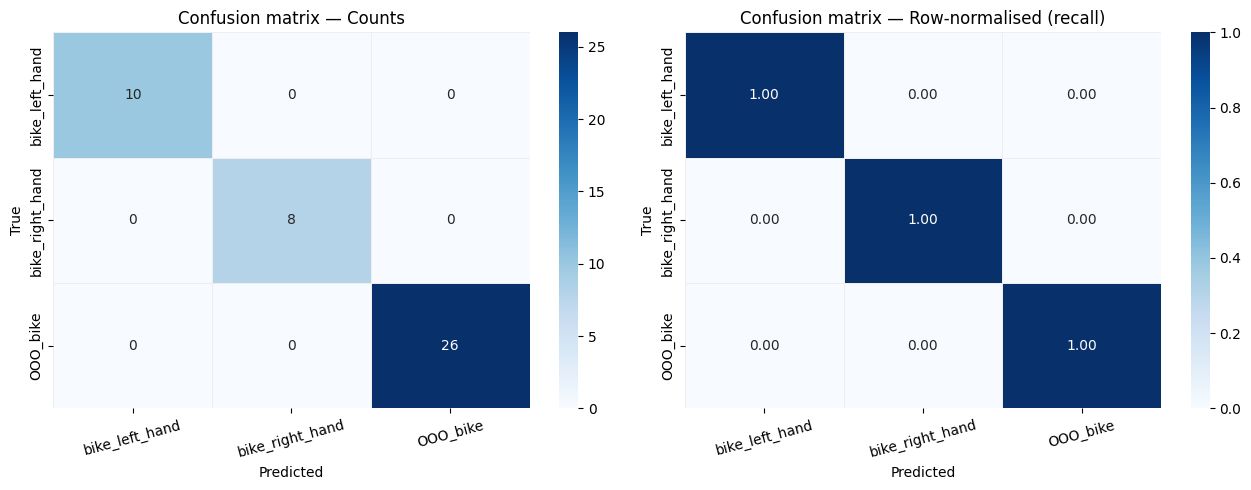

  bike_left_hand   mean confidence on correct class: 0.951
  bike_right_hand  mean confidence on correct class: 0.938
  OOO_bike         mean confidence on correct class: 0.902

0 misclassified test clips:


In [22]:
# CELL 14 — Final evaluation on the held-out TEST set (multi-view inference)
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score
import seaborn as sns

ckpt = torch.load(f"{SAVE_DIR}/best_model.pt", map_location=cfg.DEVICE)
model.load_state_dict(ckpt["state"]); model.eval()
print(f"Loaded best checkpoint — epoch {ckpt['epoch']} | val acc {ckpt['val_acc']:.4f} | val F1 {ckpt['val_f1']:.4f}")

class ClipDatasetView(ClipDataset):
    """Deterministic sampling: in every segment take the frame at relative position `frac`."""
    def __init__(self, clips, frac):
        super().__init__(clips, augment=False, verbose=False); self.frac = frac
    def _sample_frames(self, paths):
        n, T_len = len(paths), cfg.FRAMES_PER_CLIP
        e = np.linspace(0, n, T_len + 1)
        return [paths[min(n - 1, int(e[i] + self.frac * (e[i + 1] - e[i])))] for i in range(T_len)]

@torch.no_grad()
def predict_probs(clips, fracs):
    """Return softmax probabilities of shape (num_views, num_clips, num_classes)."""
    model.eval(); views = []
    for frac in fracs:
        # num_workers=0 -> no worker processes -> no multiprocessing error noise
        dl = DataLoader(ClipDatasetView(clips, frac), batch_size=cfg.BATCH_SIZE,
                        shuffle=False, num_workers=0)
        p = []
        for x, _ in tqdm(dl, leave=False, desc=f"view {frac}"):
            with torch.autocast(device_type=cfg.DEVICE, dtype=torch.float16, enabled=use_amp):
                p.append(F.softmax(model(x.to(cfg.DEVICE)).float(), dim=1).cpu())
        views.append(torch.cat(p))
    return torch.stack(views)

views      = predict_probs(test_clips, cfg.TTA_FRACS)
all_labels = np.array([c[1] for c in test_clips])
single     = views[cfg.TTA_FRACS.index(0.5)].argmax(1).numpy()     # one view only
all_preds  = views.mean(0).argmax(1).numpy()                        # average of all views

print(f"\nSingle view  : acc {accuracy_score(all_labels, single):.4f} | macro-F1 {f1_score(all_labels, single, average='macro'):.4f}")
print(f"Multi-view x{len(cfg.TTA_FRACS)}: acc {accuracy_score(all_labels, all_preds):.4f} | macro-F1 {f1_score(all_labels, all_preds, average='macro'):.4f}")

print("\n" + "=" * 65); print("  CLASSIFICATION REPORT — Test Set (multi-view)"); print("=" * 65)
print(classification_report(all_labels, all_preds, labels=list(range(cfg.NUM_CLASSES)),
                            target_names=cfg.ALL_CLASSES, digits=4, zero_division=0))

cm = confusion_matrix(all_labels, all_preds, labels=list(range(cfg.NUM_CLASSES)))
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for ax, data, fmt, title in [(axes[0], cm, "d", "Counts"),
                             (axes[1], cm / cm.sum(1, keepdims=True).clip(min=1), ".2f", "Row-normalised (recall)")]:
    sns.heatmap(data, annot=True, fmt=fmt, cmap="Blues", xticklabels=cfg.ALL_CLASSES,
                yticklabels=cfg.ALL_CLASSES, linewidths=0.5, linecolor="#eee", ax=ax)
    ax.set_xlabel("Predicted"); ax.set_ylabel("True"); ax.set_title(f"Confusion matrix — {title}")
    ax.tick_params(axis="x", rotation=15)
plt.tight_layout()
plt.savefig(f"{SAVE_DIR}/05_confusion_matrix.png", dpi=150, bbox_inches="tight")
plt.show()

# mean confidence on the correct class, per true class
mean_probs = views.mean(0).numpy()
for i, cls in enumerate(cfg.ALL_CLASSES):
    m = all_labels == i
    print(f"  {cls:<16} mean confidence on correct class: {mean_probs[m, i].mean():.3f}")

# list wrongly classified test clips
wrong = [(c[0][0].rsplit("/", 1)[0], cfg.ALL_CLASSES[l], cfg.ALL_CLASSES[p])
         for c, l, p in zip(test_clips, all_labels, all_preds) if l != p]
print(f"\n{len(wrong)} misclassified test clips:")
for path, t, p in wrong: print(f"  true={t:<16} pred={p:<16} {path}")

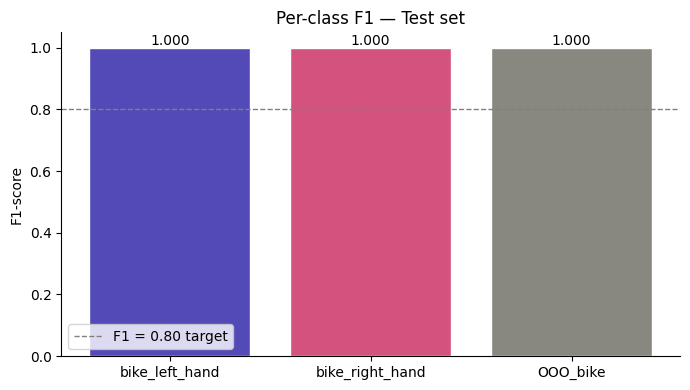

All outputs saved in: /kaggle/working/outputs


In [23]:
# CELL 15 — Per-class F1 summary
f1_scores = f1_score(all_labels, all_preds, average=None, labels=list(range(cfg.NUM_CLASSES)), zero_division=0)

fig, ax = plt.subplots(figsize=(7, 4))
bars = ax.bar(cfg.ALL_CLASSES, f1_scores, color=[palette[c] for c in cfg.ALL_CLASSES], edgecolor="white")
ax.axhline(0.80, color="gray", linestyle="--", linewidth=1, label="F1 = 0.80 target")
for b, v in zip(bars, f1_scores):
    ax.text(b.get_x() + b.get_width()/2, b.get_height() + 0.01, f"{v:.3f}", ha="center", fontsize=10)
ax.set_ylim(0, 1.05); ax.set_ylabel("F1-score"); ax.set_title("Per-class F1 — Test set")
ax.legend(); ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.savefig(f"{SAVE_DIR}/06_per_class_f1.png", dpi=150, bbox_inches="tight")
plt.show()
print("All outputs saved in:", SAVE_DIR)

In [24]:
# CELL 16 — Inference helper: classify any clip folder (multi-view)
def predict_clip(frame_paths, fracs=cfg.TTA_FRACS):
    probs = predict_probs([(sorted(frame_paths), 0, "?")], fracs).mean(0)[0].numpy()
    best  = int(probs.argmax())
    return {"prediction": cfg.ALL_CLASSES[best],
            "probs": {c: round(float(p), 4) for c, p in zip(cfg.ALL_CLASSES, probs)}}

# Example: first test clip
example_frames, example_label, example_cls = test_clips[0]
print("True     :", example_cls)
print("Predicted:", predict_clip(example_frames))

True     : bike_left_hand


view 0.1:   0%|          | 0/1 [00:00<?, ?it/s]

view 0.3:   0%|          | 0/1 [00:00<?, ?it/s]

view 0.5:   0%|          | 0/1 [00:00<?, ?it/s]

view 0.7:   0%|          | 0/1 [00:00<?, ?it/s]

view 0.9:   0%|          | 0/1 [00:00<?, ?it/s]

Predicted: {'prediction': 'bike_left_hand', 'probs': {'bike_left_hand': 0.9544, 'bike_right_hand': 0.0223, 'OOO_bike': 0.0233}}


In [25]:
import shutil, os
from IPython.display import FileLink

zip_path = shutil.make_archive("/kaggle/working/gesture_outputs", "zip", "/kaggle/working/outputs")
print(zip_path, "-", round(os.path.getsize(zip_path) / 1e6, 1), "MB")
FileLink("gesture_outputs.zip")

/kaggle/working/gesture_outputs.zip - 29.2 MB


/kaggle/working/gesture_outputs.zip